In [1]:
from pathlib import Path
import os

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Move to the project root if Jupyter starts in notebooks
if Path.cwd().name == "notebooks":
    os.chdir("..")

print("Libraries imported successfully.")
print("Project directory configured.")

Libraries imported successfully.
Project directory configured.


In [2]:
passenger_data = pd.read_csv(
    "data/processed/caa_passenger_2019_2026.csv",
    parse_dates=["date"]
)

print("Dataset shape:", passenger_data.shape)

passenger_data.head()

Dataset shape: (2553, 17)


,rundate,reporting_period,type_of_operations,airline_name,aircraft_km_x1000,no_flights,aircraft_hours,total_passengers_uplifted,seat_km_available_x1000,seat_km_used_x1000,cargo_tonnes_uplifted,total_tonne_km_available_x1000,tot_mail_tonne_km_used_x1000,total_freight_tonne_km_used_x1000,total_passenger_tonne_km_used_x1000,load_factor_pct,date
0,07/03/2019 11:11,201901,Passenger,2 EXCEL AVIATION LTD T/A THE BLADES BROADSWORD...,27,41,69,106,325,110,0,47,0,0,11,33.846154,2019-01-01
1,07/03/2019 11:11,201901,Passenger,ACROPOLIS AVIATION LTD,46,10,57,77,866,345,0,159,0,0,29,39.838337,2019-01-01
2,07/03/2019 11:11,201901,Passenger,AIRTANKER SERVICES LTD,525,84,686,4491,156825,117325,0,21431,0,0,10082,74.812689,2019-01-01
3,07/03/2019 11:11,201901,Passenger,AURIGNY AIR SERVICES,182,843,695,31662,13460,8480,28,1486,0,3,709,63.001486,2019-01-01
4,07/03/2019 11:11,201901,Passenger,BA CITYFLYER LTD,2027,3059,4376,174199,189033,118930,0,18903,0,0,10381,62.914941,2019-01-01


In [3]:
passenger_data.loc[
    passenger_data["airline_name"].str.contains(
        "BRITISH AIRWAYS|BA CITYFLYER|BA EUROFLYER",
        case=False,
        na=False
    ),
    "airline_name"
].drop_duplicates().sort_values()

4                           BA CITYFLYER LTD
1300    BA EUROFLYER LTD DBA BRITISH AIRWAYS
7                        BRITISH AIRWAYS PLC
Name: airline_name, dtype: str

In [4]:
ba_airlines = [
    "BA CITYFLYER LTD",
    "BA EUROFLYER LTD DBA BRITISH AIRWAYS",
    "BRITISH AIRWAYS PLC"
]

ba_comparison = passenger_data[
    passenger_data["airline_name"].isin(ba_airlines)
].copy()

print("Comparison dataset shape:", ba_comparison.shape)

ba_comparison["airline_name"].value_counts()

Comparison dataset shape: (225, 17)


airline_name
BA CITYFLYER LTD                        91
BRITISH AIRWAYS PLC                     91
BA EUROFLYER LTD DBA BRITISH AIRWAYS    43
Name: count, dtype: int64

In [5]:
ba_comparison.groupby("airline_name").agg(
    first_month=("date", "min"),
    last_month=("date", "max"),
    months=("date", "count")
)

,first_month,last_month,months
airline_name,,,
BA CITYFLYER LTD,2019-01-01,2026-07-01,91
BA EUROFLYER LTD DBA BRITISH AIRWAYS,2023-01-01,2026-07-01,43
BRITISH AIRWAYS PLC,2019-01-01,2026-07-01,91


In [6]:
comparison_period = ba_comparison[
    ba_comparison["date"].dt.year.between(2023, 2025)
].copy()

annual_passenger_comparison = comparison_period.pivot_table(
    index="date",
    columns="airline_name",
    values="total_passengers_uplifted",
    aggfunc="sum"
).resample("YE").sum()

annual_passenger_comparison.index = (
    annual_passenger_comparison.index.year
)

annual_passenger_comparison

airline_name,BA CITYFLYER LTD,BA EUROFLYER LTD DBA BRITISH AIRWAYS,BRITISH AIRWAYS PLC
date,,,
2023,2431759,2524523,37986293
2024,2384607,3525286,39840238
2025,2522572,3777181,39636086


In [7]:
annual_flight_comparison = (
    comparison_period
    .groupby([
        comparison_period["date"].dt.year,
        "airline_name"
    ])["no_flights"]
    .sum()
    .unstack()
)

annual_flight_comparison

airline_name,BA CITYFLYER LTD,BA EUROFLYER LTD DBA BRITISH AIRWAYS,BRITISH AIRWAYS PLC
date,,,
2023,33236,19840,239174
2024,30369,23987,249570
2025,30870,26523,251427


In [8]:
passengers_per_flight_comparison = (
    annual_passenger_comparison
    / annual_flight_comparison
)

passengers_per_flight_comparison.round(2)

airline_name,BA CITYFLYER LTD,BA EUROFLYER LTD DBA BRITISH AIRWAYS,BRITISH AIRWAYS PLC
date,,,
2023,73.17,127.24,158.82
2024,78.52,146.97,159.64
2025,81.72,142.41,157.64


In [9]:
annual_capacity = comparison_period.groupby(
    [comparison_period["date"].dt.year, "airline_name"]
)[["seat_km_available_x1000", "seat_km_used_x1000"]].sum()

annual_load_factor_comparison = (
    annual_capacity["seat_km_used_x1000"]
    / annual_capacity["seat_km_available_x1000"]
    * 100
).unstack()

annual_load_factor_comparison.round(2)

airline_name,BA CITYFLYER LTD,BA EUROFLYER LTD DBA BRITISH AIRWAYS,BRITISH AIRWAYS PLC
date,,,
2023,77.40,83.35,83.64
2024,80.30,81.97,85.38
2025,78.92,78.82,84.17


In [10]:
euroflyer_capacity = annual_capacity.xs(
    "BA EUROFLYER LTD DBA BRITISH AIRWAYS",
    level="airline_name"
)

capacity_growth = (
    (euroflyer_capacity.loc[2025] / euroflyer_capacity.loc[2023] - 1)
    * 100
)

capacity_growth.round(2)

seat_km_available_x1000    46.74
seat_km_used_x1000         38.77
dtype: float64

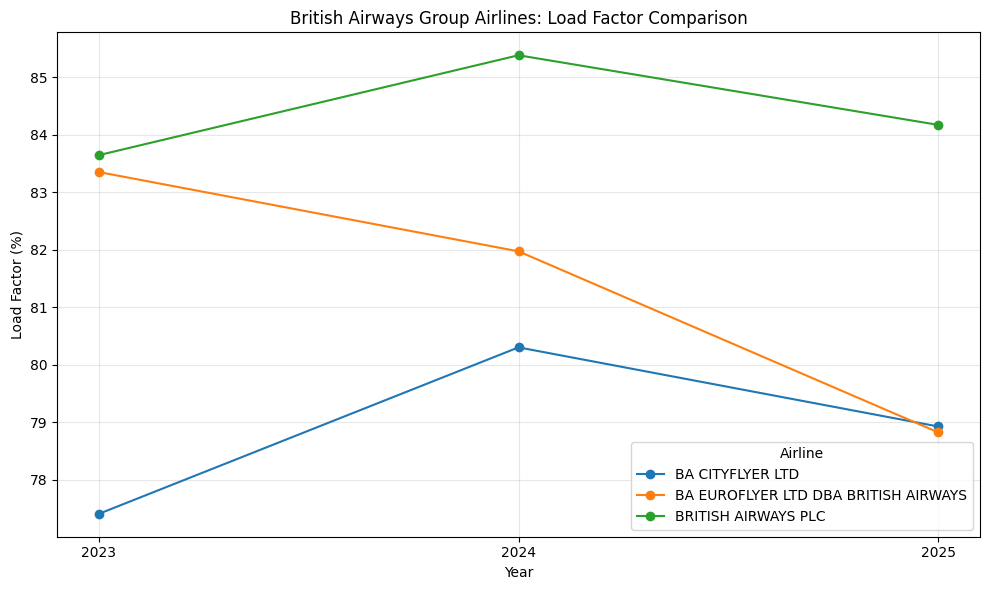

In [11]:
ax = annual_load_factor_comparison.plot(
    kind="line",
    marker="o",
    figsize=(10, 6)
)

ax.set_title("British Airways Group Airlines: Load Factor Comparison")
ax.set_xlabel("Year")
ax.set_ylabel("Load Factor (%)")
ax.set_xticks([2023, 2024, 2025])
ax.grid(True, alpha=0.3)

plt.legend(title="Airline")
plt.tight_layout()
plt.show()

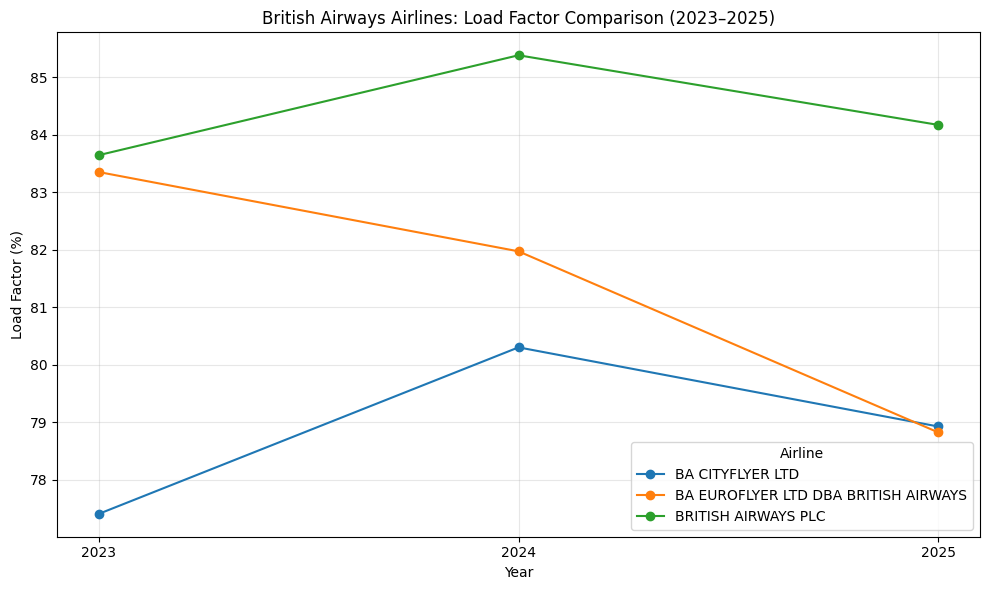

Chart saved successfully.


In [12]:
fig, ax = plt.subplots(figsize=(10, 6))

annual_load_factor_comparison.plot(
    kind="line",
    marker="o",
    ax=ax
)

ax.set_title("British Airways Airlines: Load Factor Comparison (2023–2025)")
ax.set_xlabel("Year")
ax.set_ylabel("Load Factor (%)")
ax.set_xticks([2023, 2024, 2025])
ax.grid(True, alpha=0.3)
ax.legend(title="Airline")

fig.tight_layout()

fig.savefig(
    "reports/figures/ba_airlines_load_factor_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved successfully.")

## Conclusions and Commercial Insights

### Overview

This analysis compares BA Cityflyer, BA Euroflyer and British Airways PLC using Civil Aviation Authority (CAA) passenger and capacity statistics for 2023–2025.

### Key Findings

**1. Passenger demand**

- BA Cityflyer's annual passenger numbers increased by approximately 3.7% between 2023 and 2025.
- BA Euroflyer experienced significantly stronger passenger growth of approximately 49.6%.
- British Airways PLC remained the largest operator, carrying approximately 39.6 million passengers in 2025.

**2. Flight activity**

- BA Cityflyer operated 7.1% fewer flights in 2025 than in 2023.
- BA Euroflyer increased its flight activity by approximately 33.7%.
- British Airways PLC increased its flight activity by approximately 5.1%.

**3. Passengers per flight**

- BA Cityflyyer increased its average passengers per flight from 73.17 in 2023 to 81.72 in 2025.
- BA Euroflyyer increased from 127.24 to 142.41 passengers per flight.
- British Airways PLC remained relatively stable at approximately 158 passengers per flight.

**4. Capacity utilisation**

- BA Cityflyer's load factor increased from 77.40% to 78.92%.
- BA Euroflyer's load factor declined from 83.35% to 78.82%.
- British Airways PLC maintained the highest load factor, reaching 84.17% in 2025.

### Commercial Implications

BA Cityflyer's increasing passengers per flight suggests improved utilisation of its flight activity.

BA Euroflyer's declining load factor warrants further investigation, particularly because its available seat-kilometre capacity increased faster than used capacity.

British Airways PLC maintained comparatively high load factors, although differences in aircraft size, routes and operating models must be considered.

### Limitations

- The analysis uses airline-level rather than route-level data.
- Aircraft types and seating configurations are not included.
- Passenger numbers and load factors do not directly measure profitability.
- Differences between airlines may reflect their route networks and business models.
- BA Euroflyer's separate reporting history begins in 2023.

### Overall Conclusion

The three airlines exhibit different operational patterns. BA Cityflyer improved its average passengers per flight, BA Euroflyer expanded substantially while experiencing declining load factors, and British Airways PLC maintained comparatively stable operations and high capacity utilisation.

These findings provide a foundation for further forecasting, statistical analysis and commercial decision-making.